# LAB1 - Phần 1 - Bài 2 (Trang 15-17): Tiền xử lý dữ liệu Titanic
**Phạm Quốc Thuận - 6451071076 - CNTT.64**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
np.random.seed(42)

## Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản của các thuộc tính

In [2]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df = pd.read_csv('../Dataset/titanic.csv')
print('Kích thước dữ liệu:', df.shape)
display(df.head())
df.info()
display(df.describe())

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Kích thước dữ liệu: (1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


## Câu 2: Liệt kê 5 thuộc tính có số lượng giá trị rỗng nhiều nhất

In [3]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum() / df.isnull().count() * 100).round(1).sort_values(ascending=False)
missing = pd.concat([total, percent], axis=1, keys=['Total', '%'])
missing.head(5)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


## Câu 3: Biểu đồ liên quan giữa Độ tuổi (age), Giới tính (sex) và khả năng sống sót (survived)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


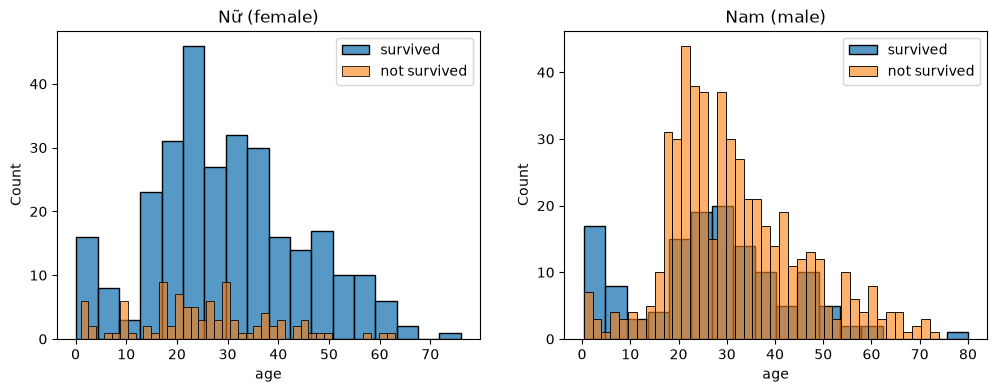

Tỉ lệ sống sót theo giới tính:
sex
female    0.727
male      0.191
Name: survived, dtype: float64

Tỉ lệ sống sót theo nhóm tuổi và giới tính:
sex        female   male
age                     
(0, 10]     0.610  0.556
(10, 18]    0.745  0.125
(18, 27]    0.733  0.194
(27, 40]    0.770  0.188
(40, 60]    0.831  0.187
(60, 100]   0.857  0.077


In [4]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, sex, title in zip(axes, ['female', 'male'], ['Nữ (female)', 'Nam (male)']):
    d = df[df['sex'] == sex]
    sns.histplot(d[d['survived'] == 1]['age'].dropna(), bins=18, label='survived', ax=ax, color='tab:blue')
    sns.histplot(d[d['survived'] == 0]['age'].dropna(), bins=40, label='not survived', ax=ax, color='tab:orange', alpha=0.6)
    ax.legend(); ax.set_title(title)
plt.show()
print('Tỉ lệ sống sót theo giới tính:')
print(df.groupby('sex')['survived'].mean().round(3))
bins = pd.cut(df['age'], [0, 10, 18, 27, 40, 60, 100])
print('\nTỉ lệ sống sót theo nhóm tuổi và giới tính:')
print(df.groupby([bins, 'sex'], observed=True)['survived'].mean().unstack().round(3))

**Nhận xét:**
- Tỉ lệ sống sót của **nữ (72,7%)** cao hơn rất nhiều so với **nam (19,1%)**, nữ ở mọi lứa tuổi đều có tỉ lệ sống sót trên 60%.
- Với nam, nhóm **trẻ em 0–10 tuổi** có tỉ lệ sống sót cao nhất (~55,6%); từ 10 tuổi trở lên tỉ lệ sống sót của nam chỉ còn khoảng 8–19%.
- Số nam không sống sót tập trung nhiều nhất ở độ tuổi khoảng 18–35.
- => Tuổi và giới tính đều ảnh hưởng mạnh tới khả năng sống sót (ưu tiên “phụ nữ và trẻ em trước”).

## Câu 4: Liên quan giữa Cổng lên tàu (embarked), Loại vé (pclass) với survived, phân biệt theo sex

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


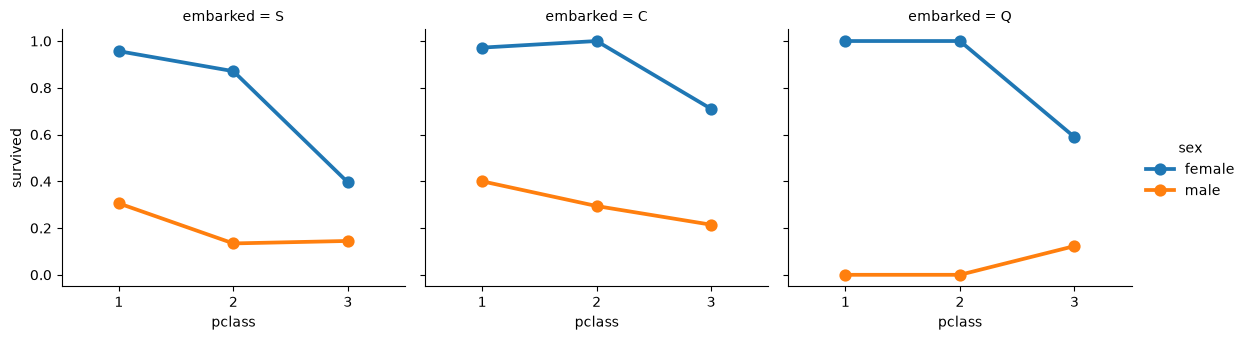

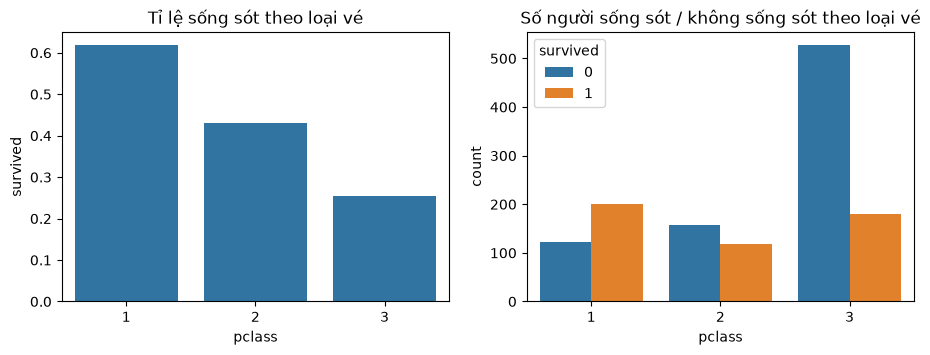

sex       female   male
embarked               
C          0.903  0.306
Q          0.617  0.111
S          0.680  0.170
pclass
1    0.619
2    0.430
3    0.255
Name: survived, dtype: float64


In [5]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
g = sns.catplot(data=df, x='pclass', y='survived', hue='sex', col='embarked',
                kind='point', col_order=['S', 'C', 'Q'], height=3.5, aspect=1.1, errorbar=None)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.barplot(data=df, x='pclass', y='survived', ax=axes[0], errorbar=None)
axes[0].set_title('Tỉ lệ sống sót theo loại vé')
sns.countplot(data=df, x='pclass', hue='survived', ax=axes[1])
axes[1].set_title('Số người sống sót / không sống sót theo loại vé')
plt.show()
print(df.pivot_table(index='embarked', columns=['sex'], values='survived', aggfunc='mean').round(3))
print(df.groupby('pclass')['survived'].mean().round(3))

**Nhận xét:**
- Cổng lên tàu có liên quan đến khả năng sống sót và phụ thuộc vào giới tính: hành khách lên tàu ở **cổng C** có tỉ lệ sống sót cao nhất ở cả nữ (90,3%) và nam (30,6%); **cổng Q** có tỉ lệ thấp nhất (nữ 61,7%, nam 11,1%).
- Ở mọi cổng, nữ luôn có tỉ lệ sống sót cao hơn nam; trong mỗi cổng, vé hạng 1 thường sống sót nhiều hơn vé hạng 3.
- Loại vé ảnh hưởng rõ rệt: **vé 1 (61,9%) > vé 2 (43,0%) > vé 3 (25,5%)**. Hành khách vé hạng 3 có số người không sống sót lớn nhất.

## Câu 5: Thống kê số người đi cùng và liên quan với thuộc tính quyết định

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số người đi một mình      : 790
Số người đi cùng người thân: 519


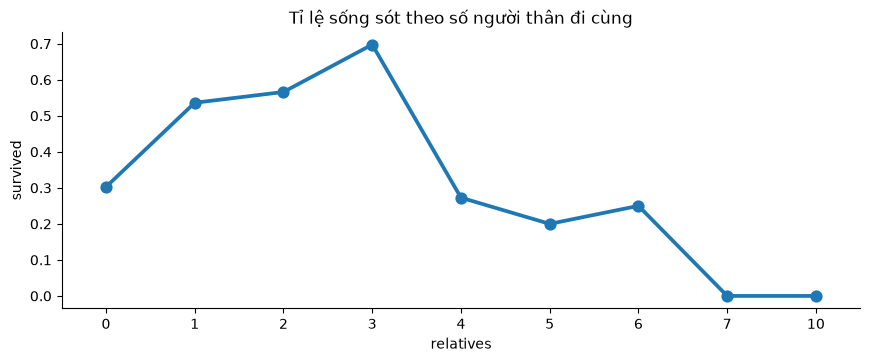

relatives       0        1        2       3       4     5      6    7     10
count      790.000  235.000  159.000  43.000  22.000  25.0  16.00  8.0  11.0
mean         0.303    0.536    0.566   0.698   0.273   0.2   0.25  0.0   0.0


In [6]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df['relatives'] = df['sibsp'] + df['parch']
df['not_alone'] = (df['relatives'] > 0).astype(int)
print('Số người đi một mình      :', (df['not_alone'] == 0).sum())
print('Số người đi cùng người thân:', (df['not_alone'] == 1).sum())
sns.catplot(data=df, x='relatives', y='survived', kind='point', height=3.5, aspect=2.5, errorbar=None)
plt.title('Tỉ lệ sống sót theo số người thân đi cùng')
plt.show()
print(df.groupby('relatives')['survived'].agg(['count', 'mean']).round(3).T)

**Nhận xét:**
- Có **790** người đi một mình và **519** người đi cùng người thân.
- Người đi một mình có tỉ lệ sống sót khoảng 30%, thấp hơn người có **1–3 người thân** đi cùng (54–70%).
- Khi số người thân từ **4 trở lên**, tỉ lệ sống sót giảm mạnh (≤ 27%); nhóm có 7 hoặc 10 người thân không ai sống sót.

## Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết

In [7]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
# Tách boong tàu (deck) từ cabin trước khi xóa cabin
df['deck'] = df['cabin'].fillna('U').str[0]
deck_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7, 'T': 8, 'U': 0}
df['deck'] = df['deck'].map(deck_map).astype(int)
print('Số giá trị khác nhau của ticket:', df['ticket'].nunique())

# Xóa các thuộc tính không cần thiết
df = df.drop(columns=['body', 'cabin', 'boat', 'home.dest', 'ticket'])

# Điền age: sinh ngẫu nhiên trong khoảng [mean - std, mean + std]
mean, std, n_null = df['age'].mean(), df['age'].std(), df['age'].isnull().sum()
df.loc[df['age'].isnull(), 'age'] = np.random.randint(int(mean - std), int(mean + std), size=n_null)

# Điền embarked bằng giá trị phổ biến nhất (mode)
print(df['embarked'].describe())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
# fare chỉ thiếu 1 giá trị -> điền bằng trung vị
df['fare'] = df['fare'].fillna(df['fare'].median())

print('\nSố giá trị rỗng sau xử lý:')
print(df.isnull().sum())
df.head()

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số giá trị khác nhau của ticket: 929
count     1307
unique       3
top          S
freq       914
Name: embarked, dtype: object

Số giá trị rỗng sau xử lý:
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         0
embarked     0
relatives    0
not_alone    0
deck         0
dtype: int64


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,211.3375,S,0,0,2
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,151.5500,S,3,1,3
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,151.5500,S,3,1,3
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,151.5500,S,3,1,3
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,151.5500,S,3,1,3


## Câu 7: Biến đổi các thuộc tính

In [8]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
# 7.1 fare -> kiểu nguyên
df['fare'] = df['fare'].astype(int)

# 7.2 Trích xuất danh hiệu (title) từ name
df['title'] = df['name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
df['title'] = df['title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major',
                                   'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['title'] = df['title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
df['title'] = df['title'].map({'Mr': 1, 'Miss': 2, 'Mrs': 3, 'Master': 4, 'Rare': 5}).fillna(0).astype(int)
df = df.drop(columns=['name'])

# 7.3 sex, embarked -> số
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
df['embarked'] = df['embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# 7.4 age -> 8 nhóm
df['age'] = df['age'].astype(int)
df['age'] = pd.cut(df['age'], bins=[-1, 11, 18, 22, 27, 33, 40, 66, 200], labels=range(8)).astype(int)
print('Số lượng mỗi nhóm tuổi:'); print(df['age'].value_counts().sort_index().to_dict())

# 7.5 fare -> 6 nhóm
df['fare'] = pd.cut(df['fare'], bins=[-1, 7.91, 14.454, 31, 99, 250, 10000], labels=range(6)).astype(int)
print('Số lượng mỗi nhóm giá vé:'); print(df['fare'].value_counts().sort_index().to_dict())
df.head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số lượng mỗi nhóm tuổi:
{0: 91, 1: 144, 2: 176, 3: 214, 4: 224, 5: 202, 6: 249, 7: 9}
Số lượng mỗi nhóm giá vé:
{0: 360, 1: 313, 2: 325, 3: 227, 4: 67, 5: 17}


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title
0,1,1,1,4,0,0,4,0,0,0,2,2
1,1,1,0,0,1,2,4,0,3,1,3,4
2,1,0,1,0,1,2,4,0,3,1,3,2
3,1,0,0,4,1,2,4,0,3,1,3,1
4,1,0,1,3,1,2,4,0,3,1,3,3
5,1,1,0,6,0,0,2,0,0,0,5,1
6,1,1,1,6,1,0,3,0,1,1,4,2
7,1,0,0,5,0,0,0,0,0,0,1,1
8,1,1,1,6,2,0,3,0,2,1,3,3
9,1,0,0,7,0,0,3,1,0,0,0,1


## Câu 8: Tạo thuộc tính mới age_class và fare_per_person

In [9]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df['age_class'] = df['age'] * df['pclass']
df['fare_per_person'] = (df['fare'] / (df['relatives'] + 1)).astype(int)
df[['pclass', 'age', 'age_class', 'fare', 'relatives', 'fare_per_person', 'survived']].head(10)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,pclass,age,age_class,fare,relatives,fare_per_person,survived
0,1,4,4,4,0,4,1
1,1,0,0,4,3,1,1
2,1,0,0,4,3,1,0
3,1,4,4,4,3,1,0
4,1,3,3,4,3,1,0
5,1,6,6,2,0,2,1
6,1,6,6,3,1,1,1
7,1,5,5,0,0,0,0
8,1,6,6,3,2,1,1
9,1,7,7,3,0,3,0
